# UCS420 – Lab Assignment 10

## Setup and imports

In [ ]:
import re
import random
from collections import Counter

import nltk

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer


paragraph = (
    "I enjoy learning about artificial intelligence because it helps computers "
    "solve problems that once required human intelligence. "
    "Machine learning systems study examples and discover useful patterns in data. "
    "I am especially interested in how robots can use sensors to understand their "
    "surroundings and make decisions. "
    "Python makes these experiments easier because it provides many powerful "
    "libraries for data analysis and model development. "
    "In the future, I hope to build reliable technology that improves education, "
    "healthcare, and everyday life."
)

Q1.  Write a unique paragraph (5-6 sentences) about your favorite topic (e.g., sports, technology, food, books, etc.).
1. Convert text to lowercase and remove punctua on using re.
2. Tokenize the text into words and sentences.
3. Split using split() and word_tokenize() and compare how Python split and NLTK’s word_tokenize() differ.
4. Remove stopwords (using NLTK's stopwords list).
5. Display word frequency distribution (excluding stopwords).

In [ ]:
# 1. Convert to lowercase and remove punctuation using re.
clean_text = re.sub(r"[^\w\s]", "", paragraph.lower())
print("\n1. Lowercase text with punctuation removed:\n", clean_text)

# 2. Tokenize into words and sentences.
word_tokens = word_tokenize(clean_text)
sentence_tokens = sent_tokenize(paragraph)

print("\n2. Word tokens:\n", word_tokens)
print("\nSentence tokens:")
for number, sentence in enumerate(sentence_tokens, start=1):
    print(f"{number}. {sentence}")

# 3. Compare Python split() with NLTK word_tokenize().
split_tokens = clean_text.split()
nltk_tokens = word_tokenize(clean_text)

print("\n3. Python split() tokens:\n", split_tokens)
print("\nNLTK word_tokenize() tokens:\n", nltk_tokens)
print("\nComparison:")
print(
    "split() separates text wherever whitespace occurs. "
    "word_tokenize() uses language-aware tokenization rules and can handle "
    "punctuation and contractions as separate tokens. Since punctuation was "
    "removed before tokenization here, the outputs may be very similar."
)

# 4. Remove stopwords.
stop_words = set(stopwords.words("english"))
filtered_tokens = [
    word for word in nltk_tokens
    if word.isalpha() and word not in stop_words
]
print("\n4. Tokens after stopword removal:\n", filtered_tokens)

# 5. Word frequency distribution excluding stopwords.
frequency = Counter(filtered_tokens)
print("\n5. Word frequency distribution (excluding stopwords):")
for word, count in frequency.most_common():
    print(f"{word}: {count}")


1. Lowercase text with punctuation removed:
 i enjoy learning about artificial intelligence because it helps computers solve problems that once required human intelligence machine learning systems study examples and discover useful patterns in data i am especially interested in how robots can use sensors to understand their surroundings and make decisions python makes these experiments easier because it provides many powerful libraries for data analysis and model development in the future i hope to build reliable technology that improves education healthcare and everyday life

2. Word tokens:
 ['i', 'enjoy', 'learning', 'about', 'artificial', 'intelligence', 'because', 'it', 'helps', 'computers', 'solve', 'problems', 'that', 'once', 'required', 'human', 'intelligence', 'machine', 'learning', 'systems', 'study', 'examples', 'and', 'discover', 'useful', 'patterns', 'in', 'data', 'i', 'am', 'especially', 'interested', 'in', 'how', 'robots', 'can', 'use', 'sensors', 'to', 'understand', 't

Q2. Using the same paragraph from Q1:
1. Extract all words with only alphabets using re.findall()
2. Remove stop words using NLTK’s stopword list
3. Perform stemming with PorterStemmer
4. Perform lemmatization on with WordNetLemmatizer
5. Compare the stemmed and lemmatized outputs and explain when you’d prefer one over the other.

In [ ]:
# 1. Extract alphabetic words using re.findall().
alphabetic_words = re.findall(r"\b[a-zA-Z]+\b", paragraph.lower())
print("\n1. Alphabetic words:\n", alphabetic_words)

# 2. Remove stopwords.
q2_filtered = [
    word for word in alphabetic_words
    if word not in stop_words
]
print("\n2. After stopword removal:\n", q2_filtered)

# 3. Perform stemming with PorterStemmer.
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(word) for word in q2_filtered]
print("\n3. PorterStemmer output:\n", stemmed_words)

# 4. Perform lemmatization with WordNetLemmatizer.
lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(word) for word in q2_filtered]
print("\n4. WordNetLemmatizer output:\n", lemmatized_words)

# 5. Compare the outputs.
print("\n5. Comparison:")
for original, stem, lemma in zip(q2_filtered, stemmed_words, lemmatized_words):
    print(f"{original:18} -> stem: {stem:14} | lemma: {lemma}")

print(
    "\nExplanation:\n"
    "Stemming removes word endings using rules and may produce a fragment "
    "that is not a dictionary word (for example, 'studies' can become "
    "'studi'). Lemmatization attempts to return a valid dictionary base form. "
    "Stemming is useful when speed and broad matching are important, such as "
    "in search indexing. Lemmatization is preferable when readable, "
    "linguistically meaningful words are important. The default WordNet "
    "lemmatizer treats words as nouns; supplying part-of-speech information "
    "can improve its results."
)


1. Alphabetic words:
 ['i', 'enjoy', 'learning', 'about', 'artificial', 'intelligence', 'because', 'it', 'helps', 'computers', 'solve', 'problems', 'that', 'once', 'required', 'human', 'intelligence', 'machine', 'learning', 'systems', 'study', 'examples', 'and', 'discover', 'useful', 'patterns', 'in', 'data', 'i', 'am', 'especially', 'interested', 'in', 'how', 'robots', 'can', 'use', 'sensors', 'to', 'understand', 'their', 'surroundings', 'and', 'make', 'decisions', 'python', 'makes', 'these', 'experiments', 'easier', 'because', 'it', 'provides', 'many', 'powerful', 'libraries', 'for', 'data', 'analysis', 'and', 'model', 'development', 'in', 'the', 'future', 'i', 'hope', 'to', 'build', 'reliable', 'technology', 'that', 'improves', 'education', 'healthcare', 'and', 'everyday', 'life']

2. After stopword removal:
 ['enjoy', 'learning', 'artificial', 'intelligence', 'helps', 'computers', 'solve', 'problems', 'required', 'human', 'intelligence', 'machine', 'learning', 'systems', 'study', 

Q3. Choose 3 short texts of your own (e.g., different news headlines, product reviews).
1. Use CountVectorizer to generate the Bag of Words representation.
2. Use TfidfVectorizer to compute TF-IDF scores.
3. Print and interpret the top 3 keywords from each text using TF-IDF.

In [11]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "Artificial intelligence helps computers learn patterns and make predictions.",
    "Electric vehicles reduce fuel consumption and can lower air pollution.",
    "Cloud computing provides storage, servers, and software through the internet."
]

print("\nThree sample texts:")
for i, text in enumerate(texts, start=1):
    print(f"Text {i}: {text}")

# 1. Bag of Words using CountVectorizer.
count_vectorizer = CountVectorizer(stop_words="english")
bow_matrix = count_vectorizer.fit_transform(texts)

print("\n1. Bag of Words feature names:")
print(count_vectorizer.get_feature_names_out())
print("\nBag of Words matrix:")
print(bow_matrix.toarray())

# 2. TF-IDF scores.
tfidf_vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)
feature_names = tfidf_vectorizer.get_feature_names_out()

print("\n2. TF-IDF matrix:")
print(tfidf_matrix.toarray())

# 3. Print and interpret the top three keywords for each text.
print("\n3. Top 3 TF-IDF keywords from each text:")
for row_number, row in enumerate(tfidf_matrix.toarray(), start=1):
    top_indices = row.argsort()[::-1][:3]
    keywords = [(feature_names[index], row[index]) for index in top_indices]
    print(f"\nText {row_number}:")
    for word, score in keywords:
        print(f"  {word}: {score:.4f}")

print(
    "\nInterpretation: Bag of Words records how often each vocabulary word "
    "appears in a document. TF-IDF gives greater importance to words that are "
    "frequent in one document but less common across the collection. The top "
    "keywords therefore indicate the terms that best distinguish each text "
    "within this small set."
)


Three sample texts:
Text 1: Artificial intelligence helps computers learn patterns and make predictions.
Text 2: Electric vehicles reduce fuel consumption and can lower air pollution.
Text 3: Cloud computing provides storage, servers, and software through the internet.

1. Bag of Words feature names:
['air' 'artificial' 'cloud' 'computers' 'computing' 'consumption'
 'electric' 'fuel' 'helps' 'intelligence' 'internet' 'learn' 'lower'
 'make' 'patterns' 'pollution' 'predictions' 'provides' 'reduce' 'servers'
 'software' 'storage' 'vehicles']

Bag of Words matrix:
[[0 1 0 1 0 0 0 0 1 1 0 1 0 1 1 0 1 0 0 0 0 0 0]
 [1 0 0 0 0 1 1 1 0 0 0 0 1 0 0 1 0 0 1 0 0 0 1]
 [0 0 1 0 1 0 0 0 0 0 1 0 0 0 0 0 0 1 0 1 1 1 0]]

2. TF-IDF matrix:
[[0.         0.35355339 0.         0.35355339 0.         0.
  0.         0.         0.35355339 0.35355339 0.         0.35355339
  0.         0.35355339 0.35355339 0.         0.35355339 0.
  0.         0.         0.         0.         0.        ]
 [0.35355339 0.   

Q4. Write 2 short texts (4–6 lines each) describing two different technologies (e.g., AI vs Blockchain).
1. Preprocess and tokenize both texts.
2. Calculate:
a. Jaccard Similarity using sets
b. Cosine Similarity using TfidfVectorizer + cosine_similarity() c. Analyze which similarity metric gives be er insights in your case.

In [12]:
technology_texts = [
    """Artificial intelligence allows computers to learn from data.
    AI systems recognize patterns and support decision making.
    They are used in healthcare, education, and transportation.
    Machine learning is an important part of modern AI.""",

    """Blockchain stores information in connected digital blocks.
    Each block is secured using cryptographic techniques.
    A distributed network helps participants verify transactions.
    Blockchain is used in finance, supply chains, and digital identity."""
]

print("\nTechnology text 1 (Artificial Intelligence):\n", technology_texts[0])
print("\nTechnology text 2 (Blockchain):\n", technology_texts[1])

# Preprocess and tokenize both texts.
def preprocess_and_tokenize(text):
    text = re.sub(r"[^a-zA-Z\s]", " ", text.lower())
    tokens = word_tokenize(text)
    return [word for word in tokens if word not in stop_words and word.isalpha()]

tokens_1 = preprocess_and_tokenize(technology_texts[0])
tokens_2 = preprocess_and_tokenize(technology_texts[1])

set_1 = set(tokens_1)
set_2 = set(tokens_2)

print("\nTokens for AI text:\n", tokens_1)
print("\nTokens for Blockchain text:\n", tokens_2)

# a. Jaccard Similarity.
intersection = set_1.intersection(set_2)
union = set_1.union(set_2)
jaccard_similarity = len(intersection) / len(union) if union else 0.0

print("\na. Jaccard Similarity:")
print("Common words:", intersection)
print("Jaccard Similarity =", round(jaccard_similarity, 4))

# b. Cosine Similarity using TF-IDF and cosine_similarity().
from sklearn.metrics.pairwise import cosine_similarity

similarity_vectorizer = TfidfVectorizer(stop_words="english")
tfidf_two_texts = similarity_vectorizer.fit_transform(technology_texts)
cosine_score = cosine_similarity(tfidf_two_texts[0:1], tfidf_two_texts[1:2])[0][0]

print("\nb. Cosine Similarity:")
print("Cosine Similarity =", round(float(cosine_score), 4))

# c. Analyze which metric gives better insight.
print(
    "\nc. Analysis:\n"
    "Jaccard Similarity compares the overlap between the two sets of unique "
    "words. It ignores how important each word is. Cosine Similarity compares "
    "the TF-IDF vectors, so it considers the relative importance of terms. "
    "For these two technology descriptions, both metrics help measure lexical "
    "overlap. Cosine Similarity generally gives more informative results when "
    "document term weights matter, while Jaccard is simpler and useful for "
    "comparing sets of unique terms."
)


Technology text 1 (Artificial Intelligence):
 Artificial intelligence allows computers to learn from data.
    AI systems recognize patterns and support decision making.
    They are used in healthcare, education, and transportation.
    Machine learning is an important part of modern AI.

Technology text 2 (Blockchain):
 Blockchain stores information in connected digital blocks.
    Each block is secured using cryptographic techniques.
    A distributed network helps participants verify transactions.
    Blockchain is used in finance, supply chains, and digital identity.

Tokens for AI text:
 ['artificial', 'intelligence', 'allows', 'computers', 'learn', 'data', 'ai', 'systems', 'recognize', 'patterns', 'support', 'decision', 'making', 'used', 'healthcare', 'education', 'transportation', 'machine', 'learning', 'important', 'part', 'modern', 'ai']

Tokens for Blockchain text:
 ['blockchain', 'stores', 'information', 'connected', 'digital', 'blocks', 'block', 'secured', 'using', 'crypt

Q5. Write a short review for a product or service.
1. Use TextBlob or VADER to find polarity & subjec vity for each review.
2. Classify reviews into Posi ve / Nega ve / Neutral.
3. Create a word cloud using the wordcloud library for all posi ve reviews.


Review sentiment results:

Review 1: This laptop is excellent. It is fast, lightweight, and the battery lasts long.
Polarity: 0.383
Subjectivity: 0.667
Classification: Positive

Review 2: The headphones are disappointing. The sound is poor and they stopped working.
Polarity: -0.200
Subjectivity: 0.567
Classification: Negative

Review 3: The phone is average. It has a normal camera and a decent screen.
Polarity: 0.056
Subjectivity: 0.572
Classification: Positive

Positive reviews used for word cloud:
['This laptop is excellent. It is fast, lightweight, and the battery lasts long.', 'The phone is average. It has a normal camera and a decent screen.']


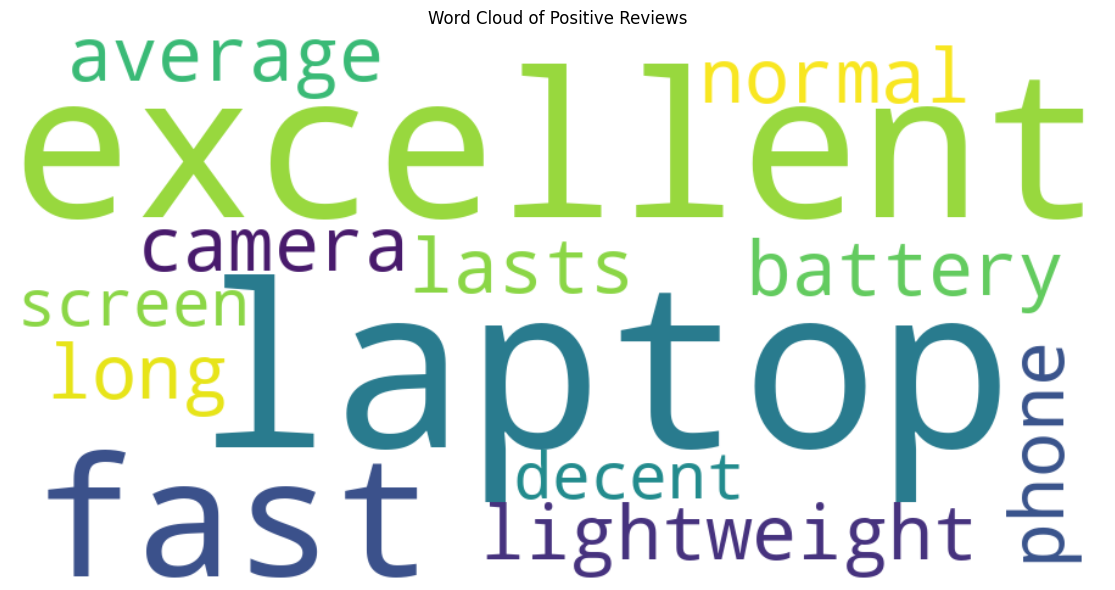


Explanation: Polarity ranges from -1 (negative) to +1 (positive), with 0 representing neutral sentiment. Subjectivity ranges from 0 (more objective) to 1 (more subjective). The classification uses the polarity thresholds shown in the program.


In [13]:
from textblob import TextBlob
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Three sample product reviews.
reviews = [
    "This laptop is excellent. It is fast, lightweight, and the battery lasts long.",
    "The headphones are disappointing. The sound is poor and they stopped working.",
    "The phone is average. It has a normal camera and a decent screen."
]

positive_reviews = []

print("\nReview sentiment results:")
for number, review in enumerate(reviews, start=1):
    blob = TextBlob(review)
    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0:
        sentiment = "Positive"
    elif polarity < 0:
        sentiment = "Negative"
    else:
        sentiment = "Neutral"

    print(f"\nReview {number}: {review}")
    print(f"Polarity: {polarity:.3f}")
    print(f"Subjectivity: {subjectivity:.3f}")
    print(f"Classification: {sentiment}")

    if sentiment == "Positive":
        positive_reviews.append(review)

# Create a word cloud from all positive reviews.
print("\nPositive reviews used for word cloud:")
print(positive_reviews)

if positive_reviews:
    positive_text = " ".join(positive_reviews)
    wordcloud = WordCloud(
        width=900,
        height=450,
        background_color="white",
        stopwords=set(stopwords.words("english"))
    ).generate(positive_text)

    plt.figure(figsize=(12, 6))
    plt.imshow(wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud of Positive Reviews")
    plt.tight_layout()
    plt.show()
else:
    print("No positive reviews were found, so a word cloud cannot be generated.")

print(
    "\nExplanation: Polarity ranges from -1 (negative) to +1 (positive), "
    "with 0 representing neutral sentiment. Subjectivity ranges from 0 "
    "(more objective) to 1 (more subjective). The classification uses the "
    "polarity thresholds shown in the program."
)

Q6. Choose your own paragraph (~100 words) as training data.
1. Tokenize text using Tokenizer() from keras.preprocessing.text
2. Create input sequences and build a simple LSTM or Dense model
3. Train the model and generate 2–3 new lines of text star ng from any seed word you provide.

In [14]:
# Approximately 100-word training paragraph.
training_text = (
    "Technology changes the way people learn, communicate, and work. "
    "Computers process information and help people solve complex problems. "
    "Artificial intelligence learns patterns from examples and can make "
    "useful predictions. Python is a popular programming language because "
    "its syntax is simple and its libraries support many applications. "
    "Students can use programming to build websites, analyze data, and "
    "automate repetitive tasks. Cloud computing provides computing resources "
    "over the internet. Cybersecurity protects systems and personal information "
    "from digital threats. Learning technology requires curiosity, practice, "
    "and patience. Small projects help learners understand concepts and gain "
    "confidence. In the future, responsible technology can improve education, "
    "healthcare, transportation, and everyday life."
)

print("\nTraining paragraph:\n", training_text)

# 1. Tokenize text using Tokenizer().
# tf.keras provides the requested Keras Tokenizer API.
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

random.seed(42)
tf.random.set_seed(42)

tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])

total_words = len(tokenizer.word_index) + 1
token_sequence = tokenizer.texts_to_sequences([training_text])[0]

print("\n1. Word index:")
print(tokenizer.word_index)
print("\nToken sequence:\n", token_sequence)
print("Vocabulary size:", total_words)

# 2. Create input sequences (progressively longer n-grams).
input_sequences = []
for i in range(1, len(token_sequence)):
    n_gram_sequence = token_sequence[:i + 1]
    input_sequences.append(n_gram_sequence)

max_sequence_len = max(len(sequence) for sequence in input_sequences)
padded_sequences = pad_sequences(
    input_sequences,
    maxlen=max_sequence_len,
    padding="pre"
)

X = padded_sequences[:, :-1]
y = padded_sequences[:, -1]

print("\n2. Number of input sequences:", len(input_sequences))
print("Input shape:", X.shape)
print("Target shape:", y.shape)

# Convert target word IDs to one-hot encoded vectors.
y = tf.keras.utils.to_categorical(y, num_classes=total_words)

# 3. Build and train a simple LSTM model.
model = Sequential([
    Embedding(input_dim=total_words, output_dim=32, input_length=max_sequence_len - 1),
    LSTM(64),
    Dense(total_words, activation="softmax")
])

model.compile(
    loss="categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

print("\n3. LSTM model summary:")
model.summary()

print("\nTraining model...")
model.fit(X, y, epochs=150, verbose=0)
print("Model training completed.")

# Generate text from a seed phrase.
def generate_text(seed_text, next_words=10):
    generated = seed_text.lower()

    for _ in range(next_words):
        sequence = tokenizer.texts_to_sequences([generated])[0]
        sequence = pad_sequences(
            [sequence],
            maxlen=max_sequence_len - 1,
            padding="pre"
        )

        probabilities = model.predict(sequence, verbose=0)[0]
        predicted_id = int(probabilities.argmax())

        if predicted_id == 0:
            break

        output_word = tokenizer.index_word.get(predicted_id, "")
        if not output_word:
            break

        generated += " " + output_word

    return generated

# 4. Generate 2–3 new lines starting from a seed word/phrase.
print("\n4. Generated text:")
seed_phrases = ["technology", "python", "artificial intelligence"]

for seed in seed_phrases:
    print(f"\nSeed: {seed}")
    print(generate_text(seed, next_words=10))

print(
    "\nNote: This is a very small training corpus, so the LSTM may repeat "
    "words or produce grammatically imperfect sentences. Better generation "
    "requires a much larger and more diverse training dataset, more training "
    "time, and careful model tuning."
)


Training paragraph:
 Technology changes the way people learn, communicate, and work. Computers process information and help people solve complex problems. Artificial intelligence learns patterns from examples and can make useful predictions. Python is a popular programming language because its syntax is simple and its libraries support many applications. Students can use programming to build websites, analyze data, and automate repetitive tasks. Cloud computing provides computing resources over the internet. Cybersecurity protects systems and personal information from digital threats. Learning technology requires curiosity, practice, and patience. Small projects help learners understand concepts and gain confidence. In the future, responsible technology can improve education, healthcare, transportation, and everyday life.

1. Word index:
{'and': 1, 'technology': 2, 'the': 3, 'can': 4, 'people': 5, 'information': 6, 'help': 7, 'from': 8, 'is': 9, 'programming': 10, 'its': 11, 'computin

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)


Training model...
Model training completed.

4. Generated text:

Seed: technology
technology the the the the and and work work and help

Seed: python
python the the the the and and work work and help

Seed: artificial intelligence
artificial intelligence the the the and and work work and help information

Note: This is a very small training corpus, so the LSTM may repeat words or produce grammatically imperfect sentences. Better generation requires a much larger and more diverse training dataset, more training time, and careful model tuning.
